In [ ]:
!gdown --fuzzy https://drive.google.com/file/d/1vxFk8ypDTqT1J3PteZIaS2d1ApPvFItz/view?usp=sharing
!unzip Merged_Split.zip
!rm -rf Merged_Split.zip


ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0)
ERROR: No matching distribution found for tensorflow==2.15.0
✓ All packages installed successfully


In [ ]:
!pip install ai-edge-model-explorer
!pip install -q tensorflow-model-optimization

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.7/84.7 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 56.6 MB/s eta 0:00:00


Found 14468 images belonging to 6 classes.

Showing augmented images for class: cardboard

cardboard - Color Adjustments Pipeline:


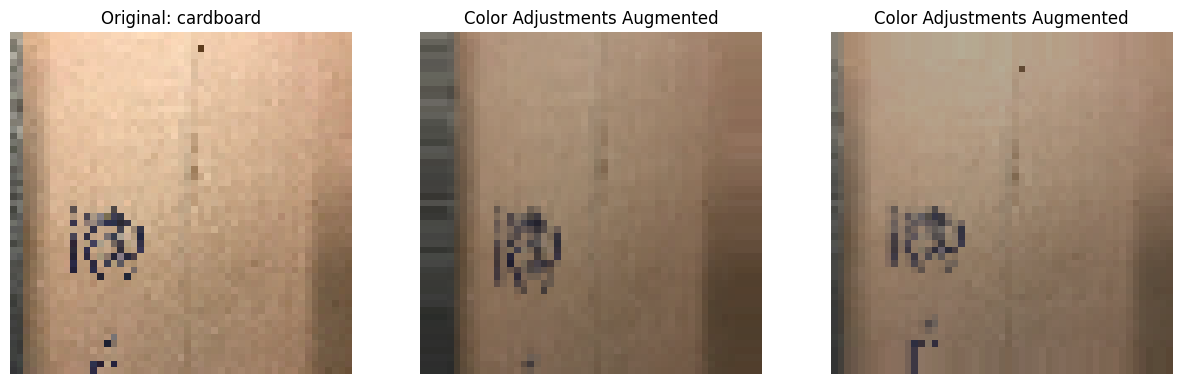


cardboard - Shifting, Rotation, Flips Pipeline:


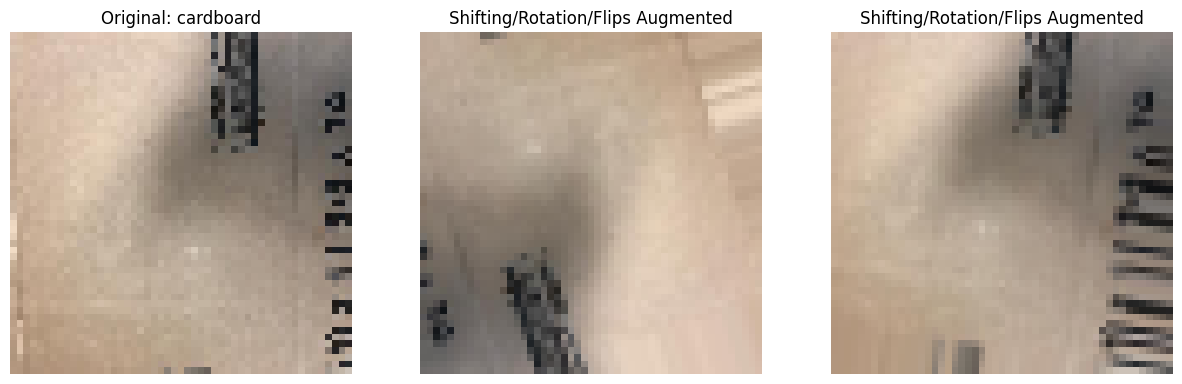


cardboard - Contrast, Zoom, Flip Pipeline:


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1263: UserWarning: This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1273: UserWarning: This ImageDataGenerator specifies `featurewise_std_normalization`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(


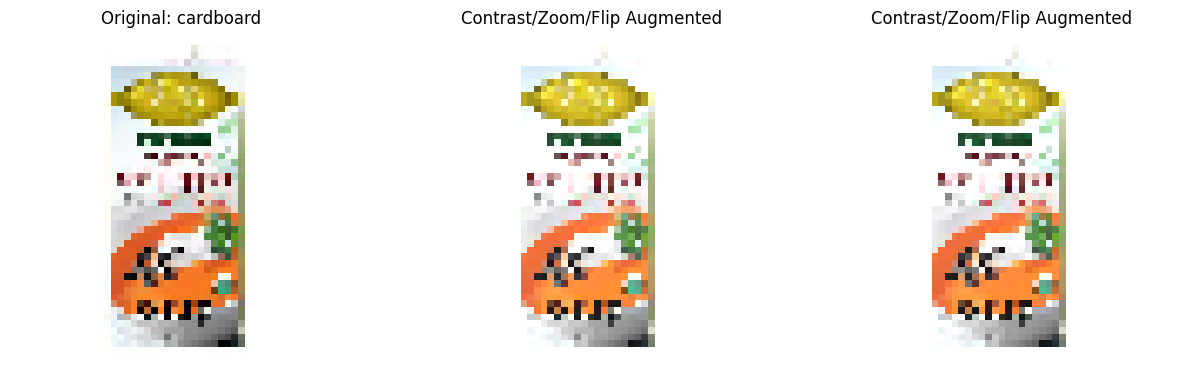


Showing augmented images for class: glass

glass - Color Adjustments Pipeline:


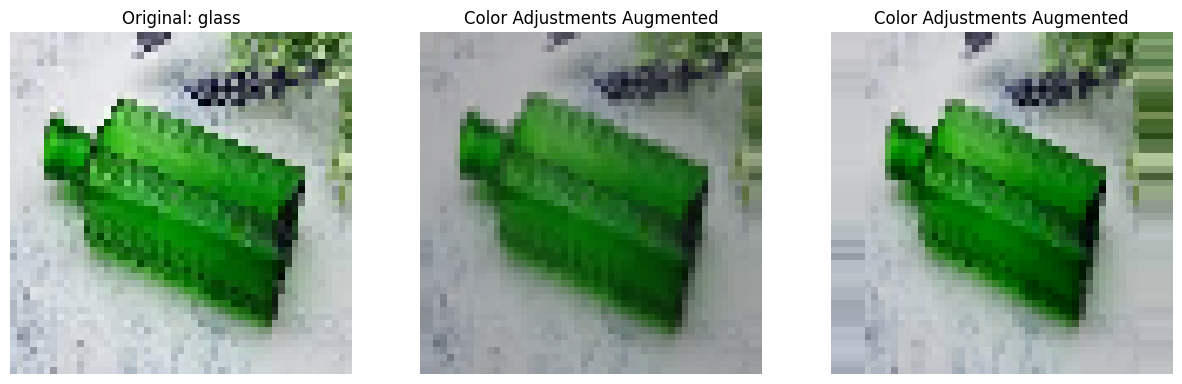


glass - Shifting, Rotation, Flips Pipeline:


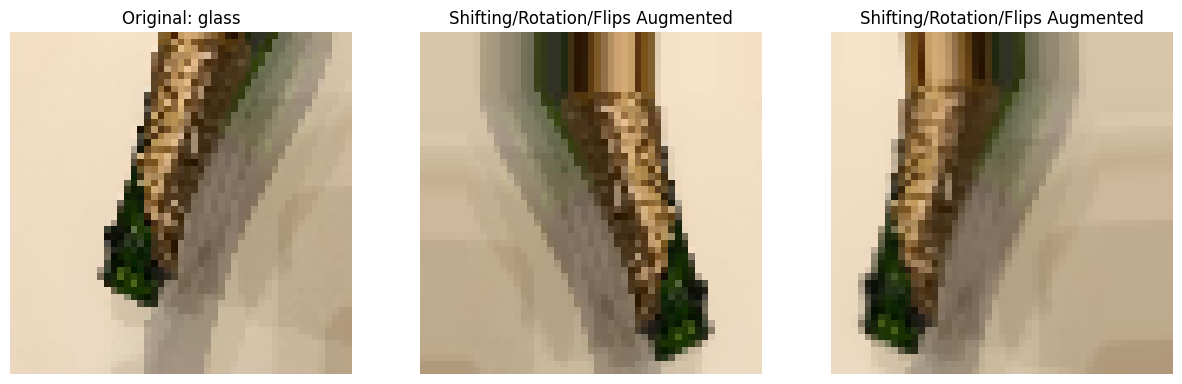


glass - Contrast, Zoom, Flip Pipeline:


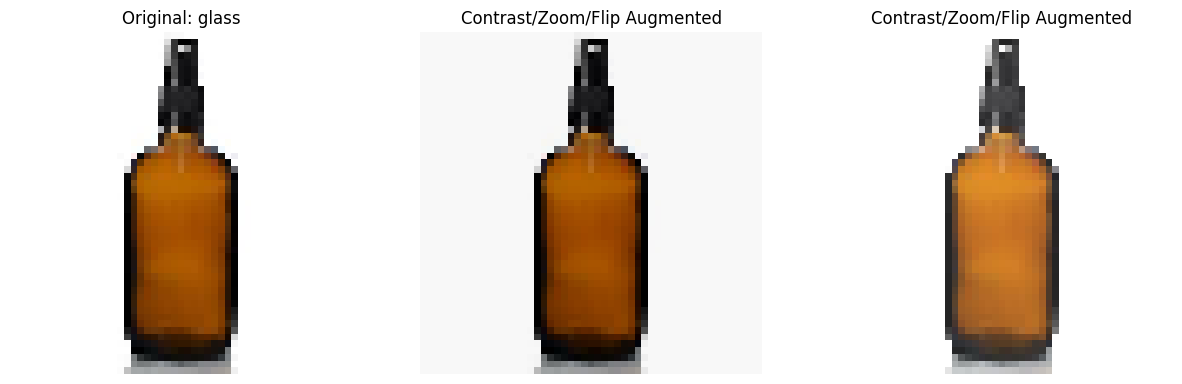


Showing augmented images for class: metal

metal - Color Adjustments Pipeline:


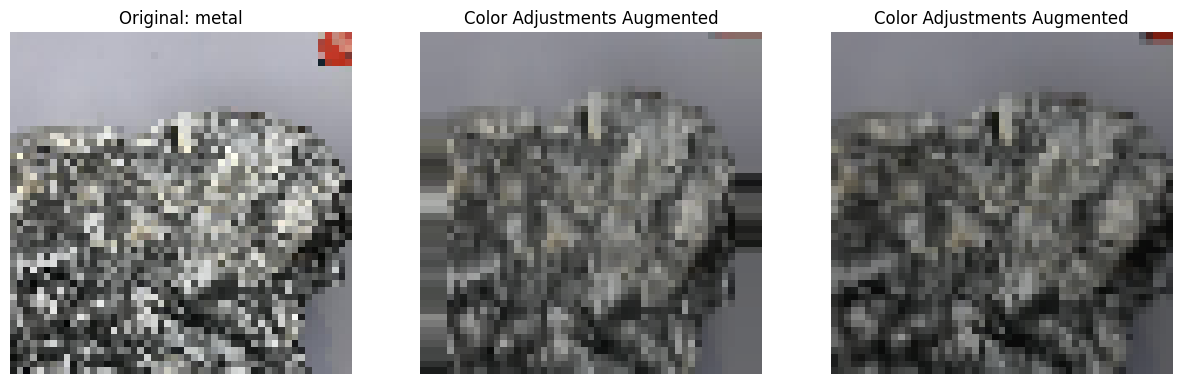


metal - Shifting, Rotation, Flips Pipeline:


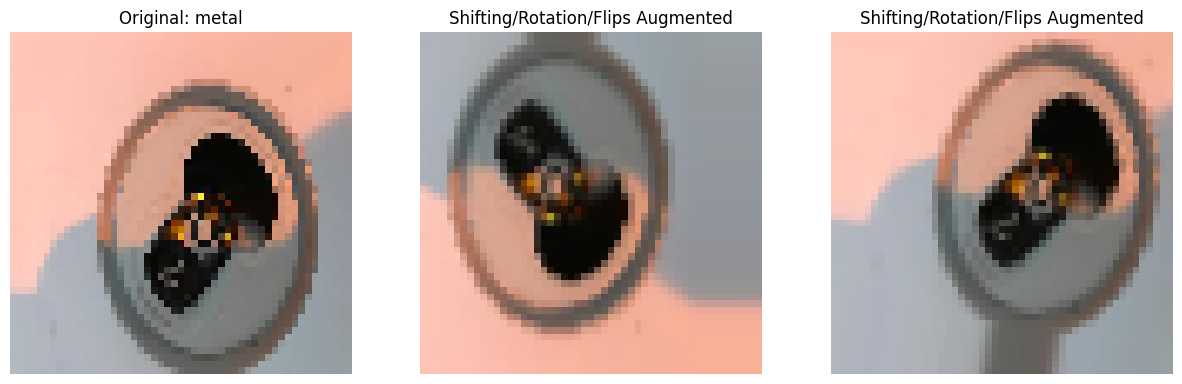


metal - Contrast, Zoom, Flip Pipeline:


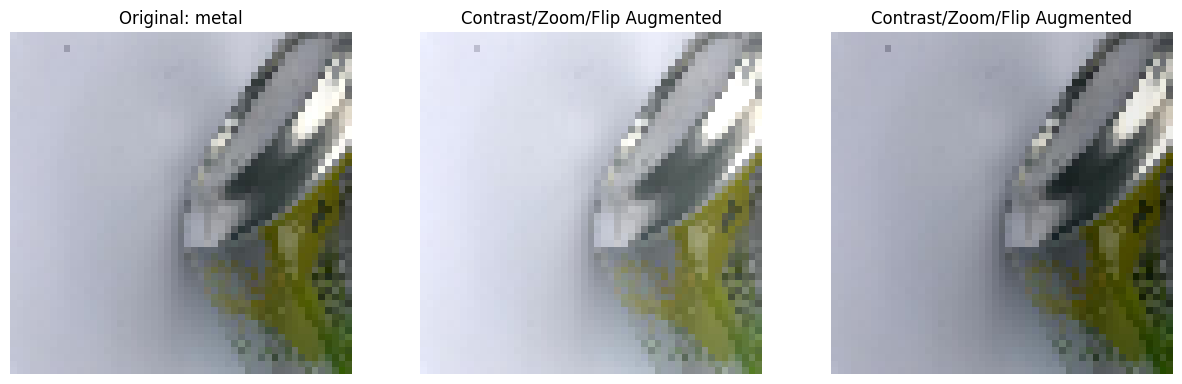


Showing augmented images for class: paper

paper - Color Adjustments Pipeline:


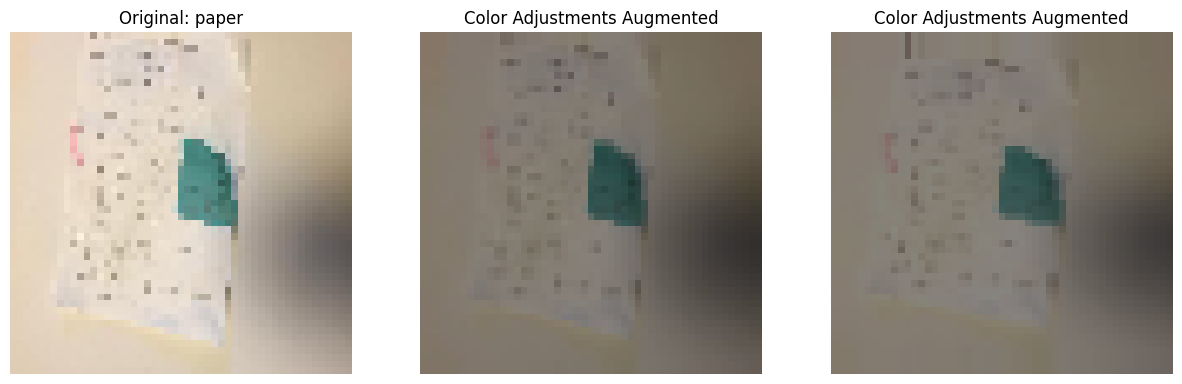


paper - Shifting, Rotation, Flips Pipeline:


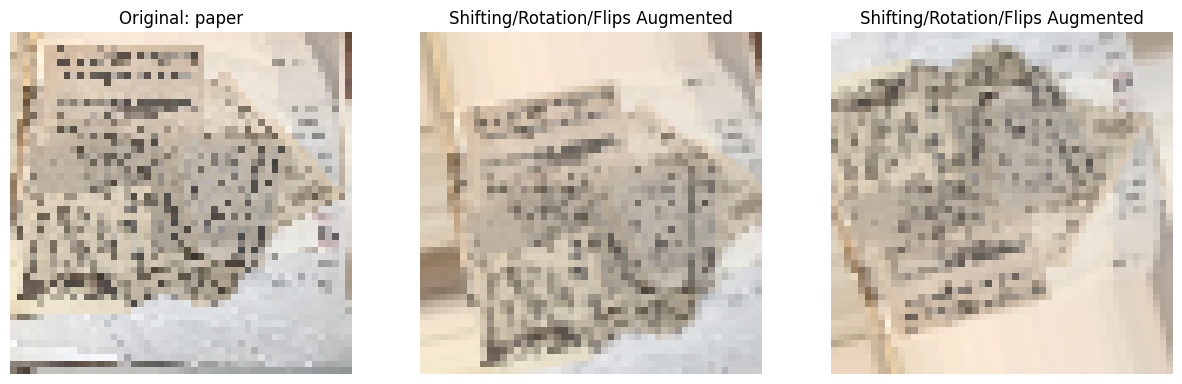


paper - Contrast, Zoom, Flip Pipeline:


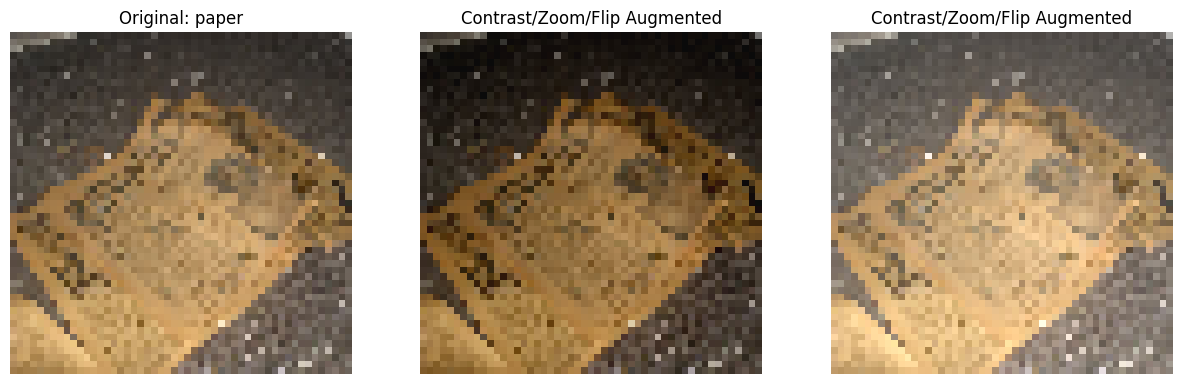


Showing augmented images for class: plastic

plastic - Color Adjustments Pipeline:


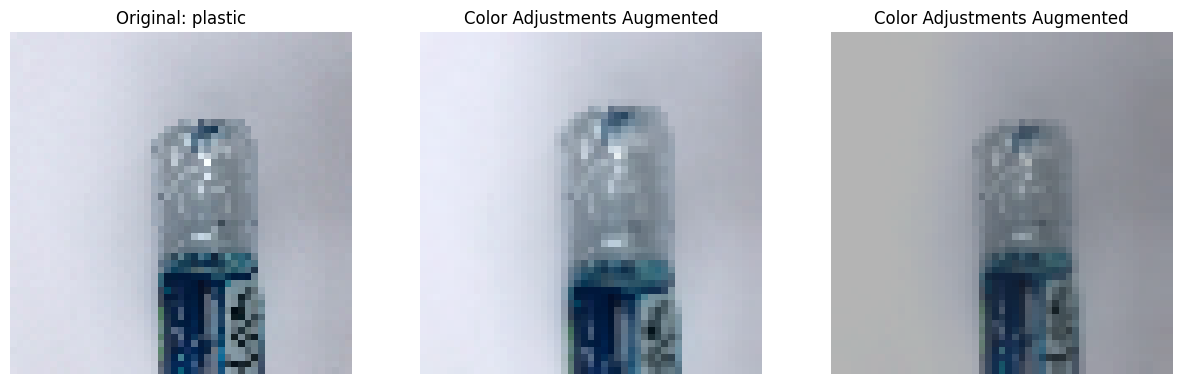


plastic - Shifting, Rotation, Flips Pipeline:


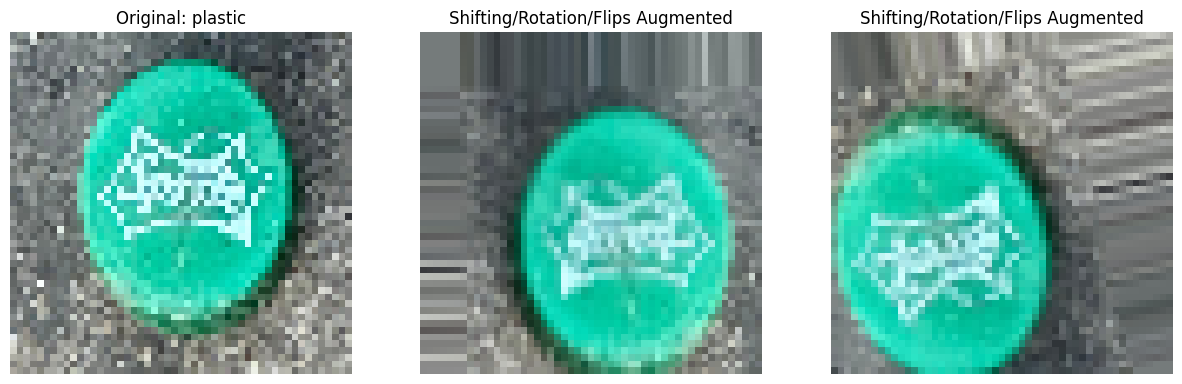


plastic - Contrast, Zoom, Flip Pipeline:


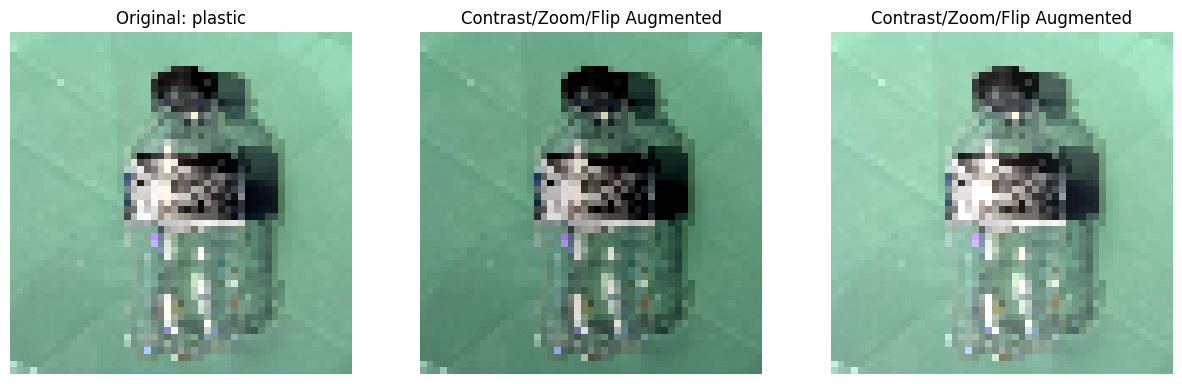


Showing augmented images for class: trash

trash - Color Adjustments Pipeline:


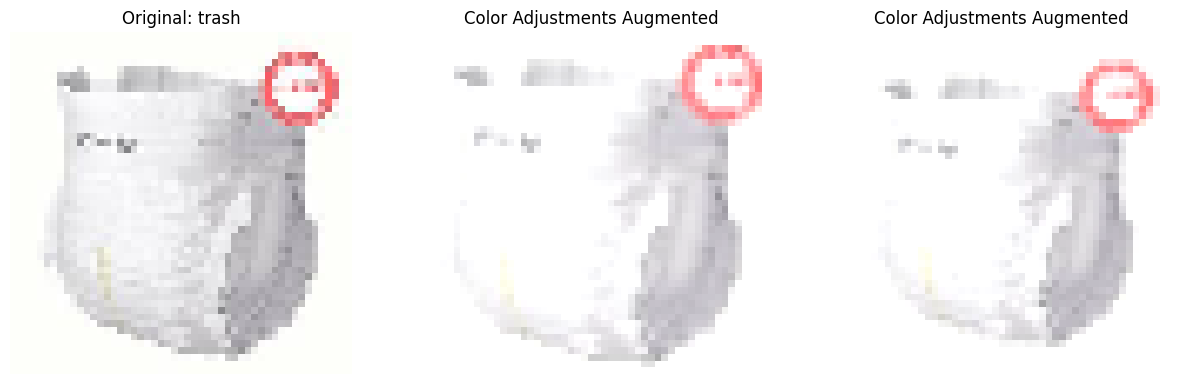


trash - Shifting, Rotation, Flips Pipeline:


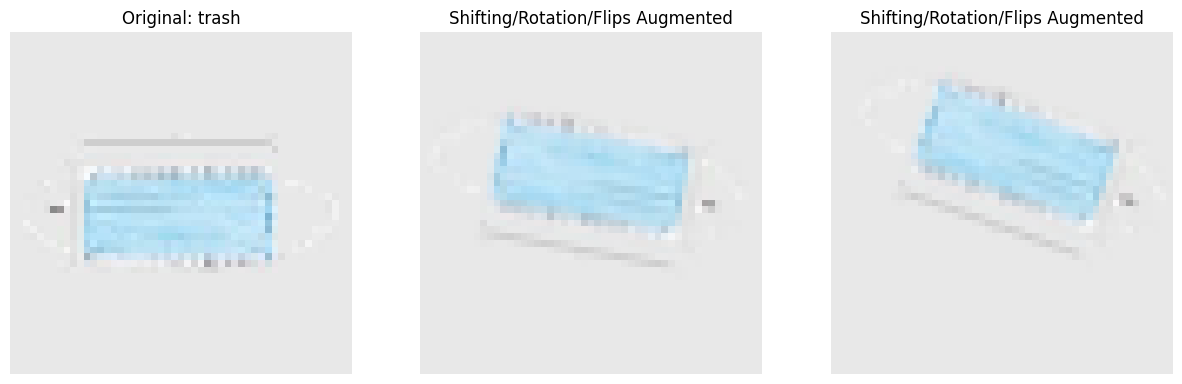


trash - Contrast, Zoom, Flip Pipeline:


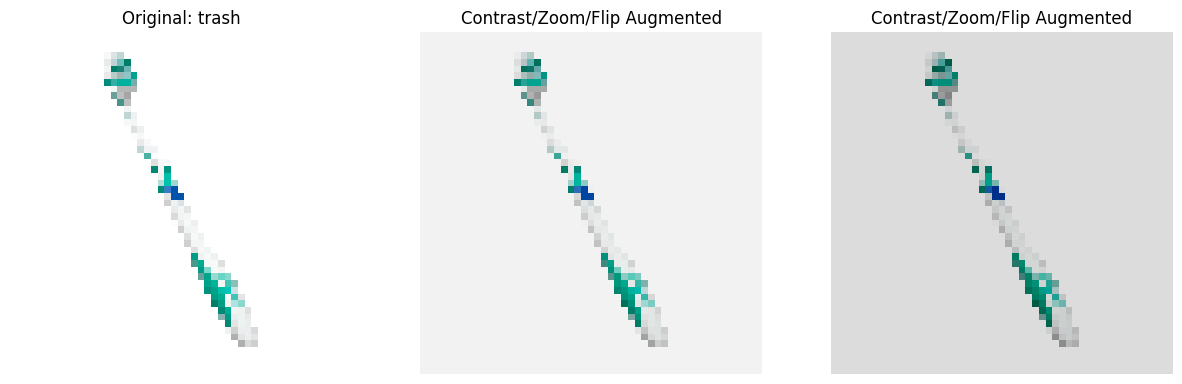

In [ ]:
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import random
import glob
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

# Directory where the dataset is stored
output_dir = '/content/Merged_Split'  # Where to save the split dataset

# Set image dimensions
BATCH_SIZE = 8
IMG_DIM = 51
NUM_CLASSES = 6

# Color adjustment augmentation pipeline
color_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    brightness_range=[0.3, 1.5],  # Random brightness adjustment
    zoom_range=0.2,               # Random zoom
    channel_shift_range=20.0      # Random channel shift
)

# Shifting, rotation, flips augmentation pipeline
shift_rotate_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    rotation_range=30,   # Random rotation
    width_shift_range=0.2,  # Random horizontal shift
    height_shift_range=0.2,  # Random vertical shift
    shear_range=0.2,     # Shear transformation
    horizontal_flip=True,  # Random horizontal flip
    vertical_flip=True     # Random vertical flip
)

# Contrast, Zoom, Flip augmentation pipeline (Removed ZCA Whitening)
contrast_zoom_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    featurewise_center=True,  # Normalize image to have zero mean
    featurewise_std_normalization=True,  # Normalize by the standard deviation
    channel_shift_range=40.0,  # Randomly shift colors of the channels
    cval=0.0  # Value to fill in for pixels outside the boundaries during transformations
)

# Load the dataset and get class indices
train_generator = color_augmentation.flow_from_directory(
    f"{output_dir}/train",
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

class_indices = train_generator.class_indices  # Get class-to-index mapping

# Function to visualize original vs augmented images
def plot_augmented_images(datagen, class_name, class_path, augmentation_type):
    img_paths = glob.glob(f"{class_path}/*.*")  # Match all image types
    if not img_paths:
        print(f"Warning: No images found in {class_path}")
        return

    random_image_path = random.choice(img_paths)
    img = keras.preprocessing.image.load_img(random_image_path, target_size=(IMG_DIM, IMG_DIM))
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = img_array.reshape((1,) + img_array.shape)  # Reshape for batch processing

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Display the original image
    axes[0].imshow(img)
    axes[0].set_title(f"Original: {class_name}")
    axes[0].axis("off")

    # Generate and display augmented images
    i = 1
    for batch in datagen.flow(img_array, batch_size=1):
        axes[i].imshow(batch[0])
        axes[i].set_title(f"{augmentation_type} Augmented")
        axes[i].axis("off")
        i += 1
        if i == 3:
            break
    plt.show()

# Loop over each class and display original vs augmented images
for class_name in sorted(class_indices.keys()):
    print(f"\nShowing augmented images for class: {class_name}")

    # Display images for color adjustment pipeline
    print(f"\n{class_name} - Color Adjustments Pipeline:")
    plot_augmented_images(color_augmentation, class_name, f"{output_dir}/train/{class_name}", "Color Adjustments")

    # Display images for shifting, rotation, flips pipeline
    print(f"\n{class_name} - Shifting, Rotation, Flips Pipeline:")
    plot_augmented_images(shift_rotate_flip_augmentation, class_name, f"{output_dir}/train/{class_name}", "Shifting/Rotation/Flips")

    # Display images for contrast, zoom, flip pipeline
    print(f"\n{class_name} - Contrast, Zoom, Flip Pipeline:")
    plot_augmented_images(contrast_zoom_flip_augmentation, class_name, f"{output_dir}/train/{class_name}", "Contrast/Zoom/Flip")

In [ ]:
import os
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tqdm.notebook import tqdm  # For progress bar
import glob

# Directory where the augmented images will be saved
augmented_dir = '/content/augmented_train_images'  # Update to your preferred directory
os.makedirs(augmented_dir, exist_ok=True)

# Augmentation pipelines (already defined in previous code)
color_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    brightness_range=[0.3, 1.5],
    zoom_range=0.2,
    channel_shift_range=20.0
)

shift_rotate_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    vertical_flip=True
)

contrast_zoom_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    featurewise_center=True,
    featurewise_std_normalization=True,
    zca_whitening=True,
    zca_epsilon=1e-06,
    channel_shift_range=40.0,
    cval=0.0,
    interpolation_order=6
)

# Function to save augmented images for a given pipeline
def save_augmented_images(datagen, class_name, class_path):
    # Create a directory to save the augmented images for each class
    class_augmented_dir = os.path.join(augmented_dir, class_name)
    os.makedirs(class_augmented_dir, exist_ok=True)

    # Get all images in the class folder
    img_paths = glob.glob(f"{class_path}/*.jpg")

    # Loop through images and apply augmentation
    for i, img_path in enumerate(tqdm(img_paths, desc=f"Saving augmented images for {class_name}", unit="image")):
        img = keras.preprocessing.image.load_img(img_path, target_size=(IMG_DIM, IMG_DIM))
        img_array = keras.preprocessing.image.img_to_array(img)
        img_array = img_array.reshape((1,) + img_array.shape)  # Reshape for batch processing

        # Apply the augmentation and save images
        for batch in datagen.flow(img_array, batch_size=1, save_to_dir=class_augmented_dir, save_prefix=f"{class_name}_aug", save_format="jpeg"):
            break  # Save one augmented image per original image

# Apply and save augmented images for each class using the three augmentation pipelines
for class_name in sorted(class_indices.keys()):
    print(f"\nProcessing class: {class_name}")

    # Save images for color adjustment pipeline
    save_augmented_images(color_augmentation, class_name, f"{output_dir}/train/{class_name}")

    # Save images for shifting, rotation, flips pipeline
    save_augmented_images(shift_rotate_flip_augmentation, class_name, f"{output_dir}/train/{class_name}")

    # Save images for contrast, zoom, flip pipeline
    save_augmented_images(contrast_zoom_flip_augmentation, class_name, f"{output_dir}/train/{class_name}")

print("\nAugmented images saved successfully!")


Processing class: cardboard


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1054: UserWarning: This ImageDataGenerator specifies `zca_whitening` which overrides setting of`featurewise_std_normalization`.
  warnings.warn(


Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

...


Processing class: trash


Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]

Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]

Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]


Augmented images saved successfully!


In [ ]:
augmented_train_dir = '/content/augmented_train_images'  # Adjust this path if your augmented train images are stored elsewhere
val_dir = '/content/Merged_Split/val'  # Your validation directory path

# Create the ImageDataGenerator for the augmented images
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # You can add other augmentations here if needed
)

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Validation set only has rescaling (no augmentation)
)

# Load the augmented training and validation data
train_dataset_tf = train_datagen.flow_from_directory(
    augmented_train_dir,  # Path to the augmented training images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=True  # Shuffle training data
)

val_dataset_tf = val_datagen.flow_from_directory(
    val_dir,  # Path to the validation images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False  # No shuffle for validation data
)
# Assuming you have a test directory similar to train and val
test_dir = '/content/Merged_Split/test'  # Adjust this path to your test directory

# Create ImageDataGenerator for test data
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Only rescaling for test data
)

# Load the test dataset
test_dataset_tf = test_datagen.flow_from_directory(
    test_dir,  # Path to the test images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False  # No shuffle for test data
)

Found 29525 images belonging to 6 classes.
Found 1810 images belonging to 6 classes.
Found 1812 images belonging to 6 classes.


In [ ]:
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import precision_score, recall_score, f1_score as sklearn_f1_score
from tensorflow.keras.callbacks import Callback
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow_model_optimization.python.core.quantization.keras import quantize
from tensorflow.keras import backend as K

# Set the random seeds for reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Image dimensions
IMG_DIM = 51  # Matches your original specification
NUM_CLASSES = 6  # Number of classes in your dataset

# F1 Score Callback for validation
class F1ScoreCallback(Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.validation_data = validation_data

    def on_epoch_end(self, epoch, logs=None):
        # Predict and convert to class indices
        val_pred = np.argmax(self.model.predict(self.validation_data[0]), axis=1)

        # Convert one-hot encoded labels back to class indices
        val_true = np.argmax(self.validation_data[1], axis=1)

        # Calculate F1 score
        f1 = sklearn_f1_score(val_true, val_pred, average='weighted')

        logs['val_f1_score'] = f1
        print(f" - val_f1_score: {f1}")

# Model creation function
def create_model():
    """
    Create a sequential model with depthwise separable convolutions
    and fully connected layers for image classification.

    Returns:
        keras.Sequential: Compiled neural network model
    """
    model = keras.Sequential([
        # First Convolution layer
        keras.layers.Conv2D(64, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Dropout(0.25),

        # Second Convolution layer
        keras.layers.Conv2D(64, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Dropout(0.25),

        # Third Convolution layer
        keras.layers.Conv2D(128, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Dropout(0.25),

        # Fourth Convolution layer
        keras.layers.Conv2D(128, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Dropout(0.25),

        # Fifth Convolution layer
        keras.layers.Conv2D(256, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Dropout(0.25),

        # Use GlobalAveragePooling2D instead of Flatten to handle the reduced feature map size
        keras.layers.GlobalAveragePooling2D(),

        # Fully connected layer
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.5),

        # Output layer (6 classes)
        keras.layers.Dense(6, activation='softmax')
])


    # Compile the model
    model.compile(
        loss=keras.losses.categorical_crossentropy,
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        metrics=['accuracy']
    )

    return model

# Create the model
tf_model = create_model()

# Save the model
keras_file = "model.h5"
keras.models.save_model(tf_model, keras_file)

# Print model summary
tf_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 51, 51, 64)        1792      
                                                                 
 max_pooling2d (MaxPooling2  (None, 25, 25, 64)        0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 25, 25, 64)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 25, 25, 64)        36928     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 12, 12, 64)        0         
 g2D)                                                            
                                                                 
 dropout_1 (Dropout)         (None, 12, 12, 64)        0

<ipython-input-6-ec8ca5da796c>:101: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  keras.models.save_model(tf_model, keras_file)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Epoch 1/50
3691/3691 [==============================] - ETA: 0s - loss: 1.6425 - accuracy: 0.3173
Epoch 1: val_accuracy improved from -inf to 0.45912, saving model to /content/best_model.h5


/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


57/57 [==============================] - 4s 74ms/step
 - val_f1_score: 0.4335763243453803
3691/3691 [==============================] - 420s 113ms/step - loss: 1.6425 - accuracy: 0.3173 - val_loss: 1.4434 - val_accuracy: 0.4591 - val_f1_score: 0.4336
Epoch 2/50
3691/3691 [==============================] - ETA: 0s - loss: 1.3893 - accuracy: 0.4652
Epoch 2: val_accuracy improved from 0.45912 to 0.55525, saving model to /content/best_model.h5


...

57/57 [==============================] - 6s 104ms/step
 - val_f1_score: 0.8905567888228868
3691/3691 [==============================] - 419s 114ms/step - loss: 0.2667 - accuracy: 0.9076 - val_loss: 0.3686 - val_accuracy: 0.8906 - val_f1_score: 0.8906
Epoch 48/50
3691/3691 [==============================] - ETA: 0s - loss: 0.2576 - accuracy: 0.9107
Epoch 48: val_accuracy improved from 0.89061 to 0.89282, saving model to /content/best_model.h5


/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


57/57 [==============================] - 5s 89ms/step
 - val_f1_score: 0.8929200141891641
3691/3691 [==============================] - 413s 112ms/step - loss: 0.2576 - accuracy: 0.9107 - val_loss: 0.3648 - val_accuracy: 0.8928 - val_f1_score: 0.8929
Epoch 49/50
3691/3691 [==============================] - ETA: 0s - loss: 0.2566 - accuracy: 0.9106
Epoch 49: val_accuracy did not improve from 0.89282
57/57 [==============================] - 5s 84ms/step
 - val_f1_score: 0.8842754172381059
3691/3691 [==============================] - 406s 110ms/step - loss: 0.2566 - accuracy: 0.9106 - val_loss: 0.4023 - val_accuracy: 0.8829 - val_f1_score: 0.8843
Epoch 50/50
3691/3691 [==============================] - ETA: 0s - loss: 0.2498 - accuracy: 0.9140
Epoch 50: val_accuracy did not improve from 0.89282
57/57 [==============================] - 5s 80ms/step
 - val_f1_score: 0.8760887248985545
3691/3691 [==============================] - 410s 111ms/step - loss: 0.2498 - accuracy: 0.9140 - val_loss: 0

/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(



Training metrics saved to /content/drive/MyDrive/paper1/training_metrics.csv
227/227 [==============================] - 32s 140ms/step
Validation F1 Score: 0.8761


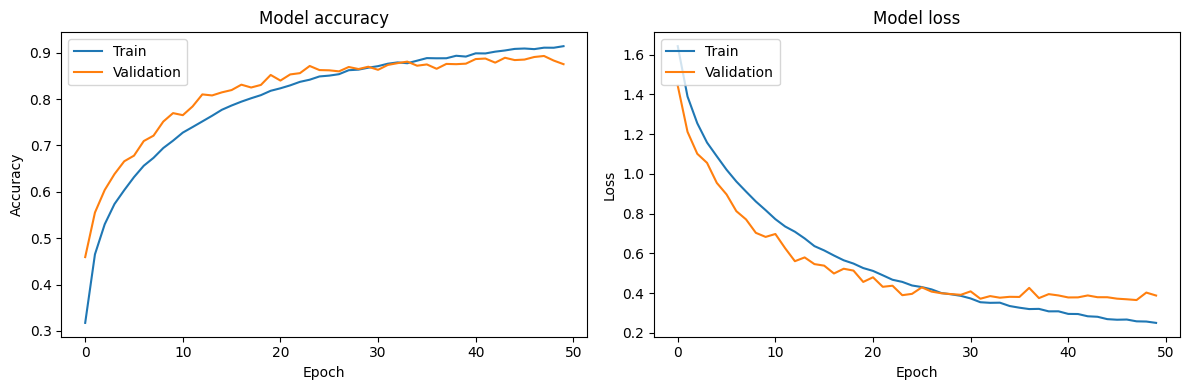

In [ ]:
from tqdm.keras import TqdmCallback
import numpy as np
import tensorflow as tf
from sklearn.metrics import f1_score as sklearn_f1_score
import pandas as pd
# Recompile the model without custom F1 score metric
tf_model.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=['accuracy'],
    run_eagerly=False  # Set to True only for debugging
)

# F1 Score Callback
class F1ScoreCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.validation_data = validation_data

    def on_epoch_end(self, epoch, logs=None):
        # Predict and convert to class indices
        val_pred = np.argmax(self.model.predict(self.validation_data[0]), axis=1)

        # Convert one-hot encoded labels back to class indices
        val_true = np.argmax(self.validation_data[1], axis=1)

        # Calculate F1 score
        f1 = sklearn_f1_score(val_true, val_pred, average='weighted')

        logs['val_f1_score'] = f1
        print(f" - val_f1_score: {f1}")

# Calculate steps per epoch for training and validation
steps_per_epoch_train = np.ceil(train_dataset_tf.samples / BATCH_SIZE).astype(int)
steps_per_epoch_val = np.ceil(val_dataset_tf.samples / BATCH_SIZE).astype(int)

# Number of epochs for training
epochs = 50
# Learning rate scheduler
# scheduler = tf.keras.callbacks.ReduceLROnPlateau(
#     monitor='val_loss',
#     factor=0.5,
#     patience=3,
#     min_lr=1e-6,
#     verbose=1
# )

# Model checkpoint to save the best model
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='/content/best_model.h5',
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

# F1 Score Callback (requires converting generator to numpy arrays)
val_X, val_y = [], []
for _ in range(steps_per_epoch_val):
    batch_X, batch_y = next(val_dataset_tf)
    val_X.append(batch_X)
    val_y.append(batch_y)
val_X = np.vstack(val_X)
val_y = np.vstack(val_y)

f1_callback = F1ScoreCallback(validation_data=(val_X, val_y))

# Train the model with progress bar
history = tf_model.fit(
    train_dataset_tf,
    steps_per_epoch=steps_per_epoch_train,
    epochs=epochs,
    validation_data=val_dataset_tf,
    validation_steps=steps_per_epoch_val,
    callbacks=[
        TqdmCallback(),  # Progress bar
        #scheduler,       # Learning rate scheduler
        checkpoint,      # Model checkpoint
        f1_callback      # F1 Score Callback
    ]
)

# Save the trained model to /content directory
tf_model.save('/content/saved_model.h5')

print("\nModel training complete and saved to /content/saved_model.h5")
# Save training metrics to CSV
history_dict = history.history
num_epochs = len(history_dict['loss'])

# Add val_f1_score from callback if not present
if 'val_f1_score' not in history_dict:
    history_dict['val_f1_score'] = f1_callback.f1_scores

history_df = pd.DataFrame({
    'epoch': range(1, num_epochs + 1),
    'accuracy': history_dict['accuracy'],
    'loss': history_dict['loss'],
    'val_accuracy': history_dict['val_accuracy'],
    'val_loss': history_dict['val_loss'],
    'val_f1_score': history_dict['val_f1_score'],
})

csv_path = '/content/drive/MyDrive/paper1/training_metrics.csv'
history_df.to_csv(csv_path, index=False)
print(f"\nTraining metrics saved to {csv_path}")
# For evaluation after training, use sklearn's f1_score with generator
# Get predictions
val_dataset_tf.reset()
val_preds = tf_model.predict(val_dataset_tf, steps=steps_per_epoch_val)
val_pred_classes = np.argmax(val_preds, axis=-1)

# Get true labels
val_dataset_tf.reset()
true_labels = []
for i in range(steps_per_epoch_val):
    _, batch_y = next(val_dataset_tf)
    true_labels.append(batch_y)
true_labels = np.vstack(true_labels)
true_classes = np.argmax(true_labels[:len(val_pred_classes)], axis=-1)

# Calculate F1 score
val_f1 = sklearn_f1_score(true_classes, val_pred_classes, average='weighted')
print(f"Validation F1 Score: {val_f1:.4f}")

# Optional: Visualize training history
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

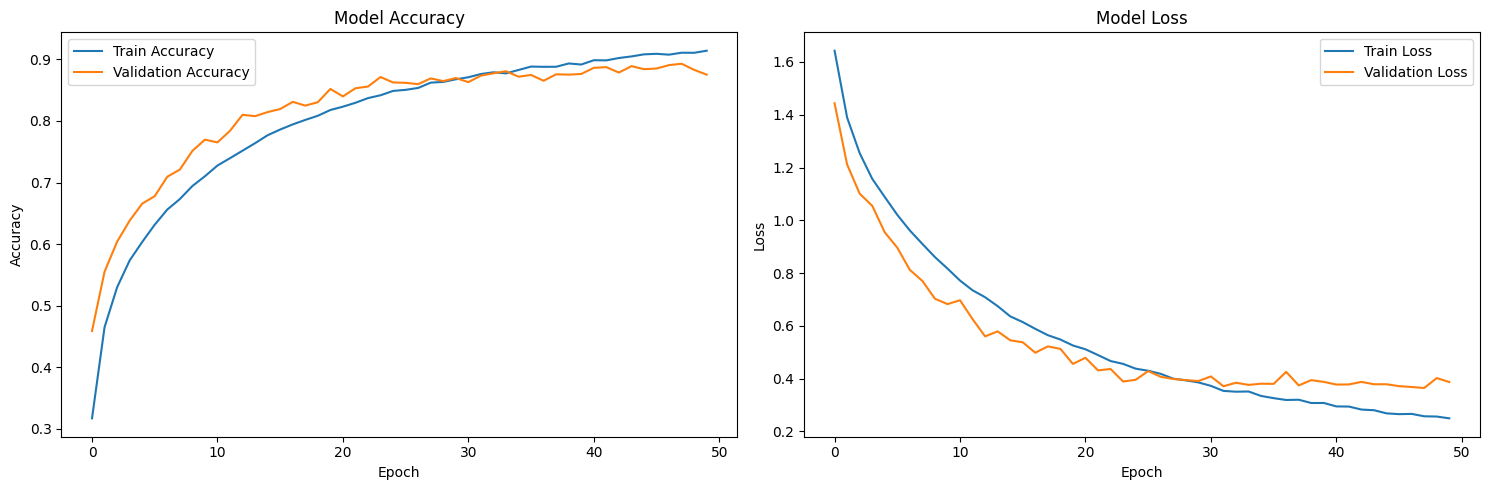

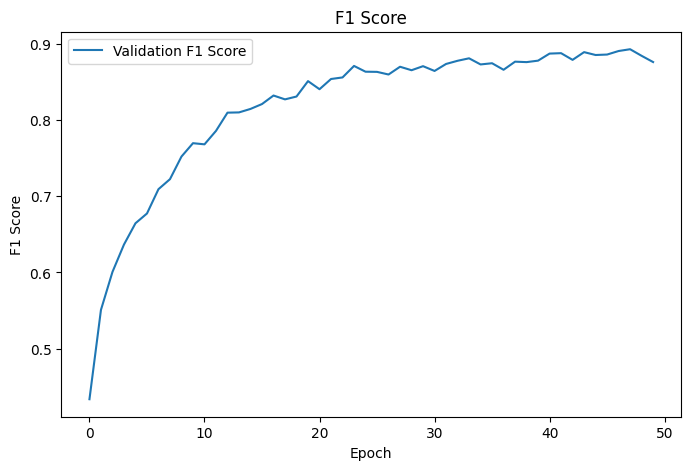

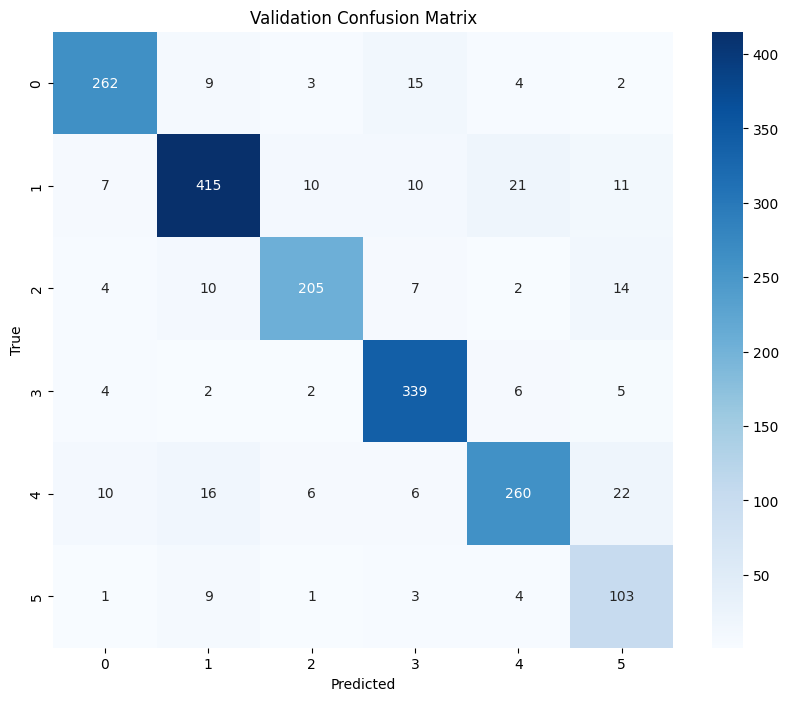

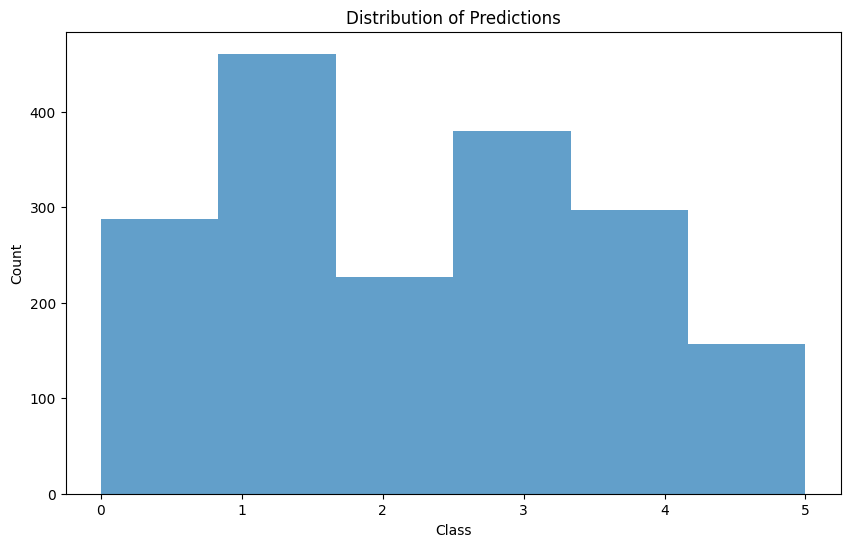

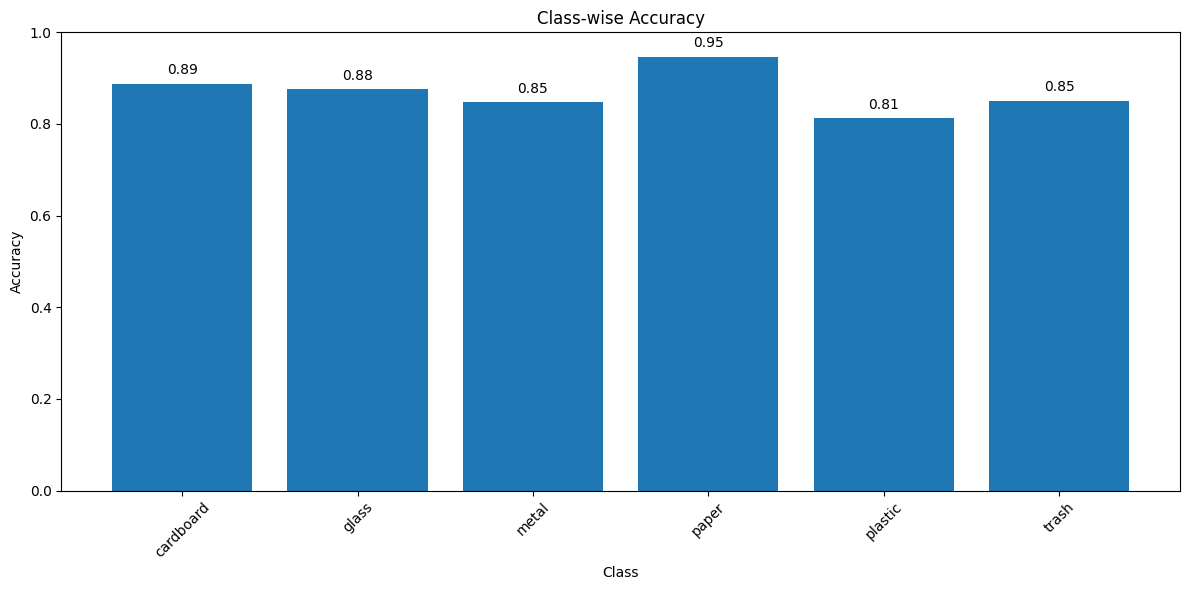

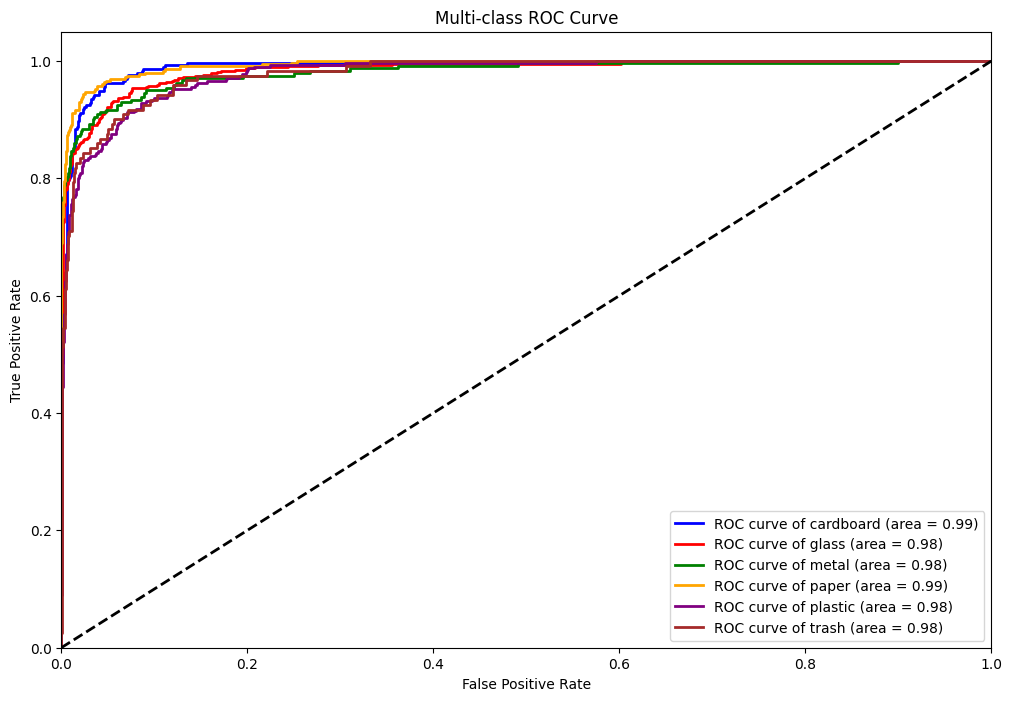

Created model performance dashboard at /content/model_performance_dashboard.png
All visualizations complete!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc
from itertools import cycle
from PIL import Image
import os

# 1. Training History Visualization
plt.figure(figsize=(15, 5))

# Plot training & validation accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('/content/training_history.png')
plt.show()

# 2. F1 Score Visualization
# Since we added a custom callback, F1 score won't be in history by default
if 'val_f1_score' in history.history:
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['val_f1_score'], label='Validation F1 Score')
    plt.title('F1 Score')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.savefig('/content/f1_score_history.png')
    plt.show()

# 3. Confusion Matrix for Validation Set
plt.figure(figsize=(10, 8))
cm = confusion_matrix(true_classes, val_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.savefig('/content/confusion_matrix.png')
plt.show()

# 4. Prediction Distribution
plt.figure(figsize=(10, 6))
plt.hist(val_pred_classes, bins=len(np.unique(val_pred_classes)), alpha=0.7)
plt.title('Distribution of Predictions')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(np.unique(val_pred_classes))
plt.savefig('/content/prediction_distribution.png')
plt.show()

# 5. Class-wise Accuracy
# Use class indices from the dataset if available
try:
    class_names = list(val_dataset_tf.class_indices.keys())
except AttributeError:
    class_names = [f'Class {i}' for i in range(len(np.unique(true_classes)))]

class_accuracy = []

# Calculate accuracy per class
for i in range(len(class_names)):
    class_mask = (true_classes == i)
    if np.sum(class_mask) > 0:  # Avoid division by zero
        accuracy = np.sum(val_pred_classes[class_mask] == i) / np.sum(class_mask)
        class_accuracy.append(accuracy)
    else:
        class_accuracy.append(0)

# Plot class-wise accuracy
plt.figure(figsize=(12, 6))
plt.bar(range(len(class_names)), class_accuracy)
plt.title('Class-wise Accuracy')
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(range(len(class_names)), class_names, rotation=45)
for i, v in enumerate(class_accuracy):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
plt.tight_layout()
plt.savefig('/content/class_accuracy.png')
plt.show()
# 6. ROC Curve for Multi-class (One-vs-Rest approach)
plt.figure(figsize=(12, 8))

# Get one-hot encoded true labels from the saved true_labels
y_test = true_labels[:len(val_pred_classes)]
y_score = val_preds  # Predicted probabilities

n_classes = y_test.shape[1]
fpr = dict()
tpr = dict()
roc_auc = dict()

# Compute ROC curve and ROC area for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {class_names[i]} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.savefig('/content/roc_curve.png')
plt.show()

# 7. Create a dashboard summary image
# Check if all the required images exist
image_paths = [
    '/content/training_history.png',
    '/content/confusion_matrix.png',
    '/content/class_accuracy.png',
    '/content/prediction_distribution.png'
]

existing_images = [path for path in image_paths if os.path.exists(path)]

if len(existing_images) >= 2:
    # Create a dashboard of existing images
    images = [Image.open(img_path) for img_path in existing_images]

    # Calculate the grid dimensions
    n_images = len(images)
    cols = min(2, n_images)
    rows = (n_images + cols - 1) // cols

    # Get max width and height for each column and row
    widths = [max(images[j].width for j in range(i, min(i+cols, n_images)))
              for i in range(0, n_images, cols)]
    heights = [max(images[i*cols + j].height for j in range(min(cols, n_images - i*cols)))
               for i in range(rows)]

    # Create the dashboard
    total_width = sum(widths)
    total_height = sum(heights)
    dashboard = Image.new('RGB', (total_width, total_height), (255, 255, 255))

    # Paste images
    y_offset = 0
    for i in range(rows):
        x_offset = 0
        for j in range(cols):
            idx = i * cols + j
            if idx < n_images:
                dashboard.paste(images[idx], (x_offset, y_offset))
                x_offset += images[idx].width
        y_offset += max(images[i*cols].height for i in range(min(cols, n_images - i*cols)))

    # Save the dashboard
    dashboard.save('/content/model_performance_dashboard.png')
    print("Created model performance dashboard at /content/model_performance_dashboard.png")

print("All visualizations complete!")

Found 1812 images belonging to 6 classes.
57/57 [==============================] - 36s 644ms/step
Classification Report:
              precision    recall  f1-score   support

   cardboard       0.91      0.85      0.88       295
       glass       0.92      0.87      0.89       474
       metal       0.91      0.91      0.91       242
       paper       0.87      0.89      0.88       359
     plastic       0.83      0.82      0.83       320
       trash       0.66      0.86      0.74       122

    accuracy                           0.87      1812
   macro avg       0.85      0.87      0.86      1812
weighted avg       0.87      0.87      0.87      1812

Classification report saved at /content/classification_report.txt


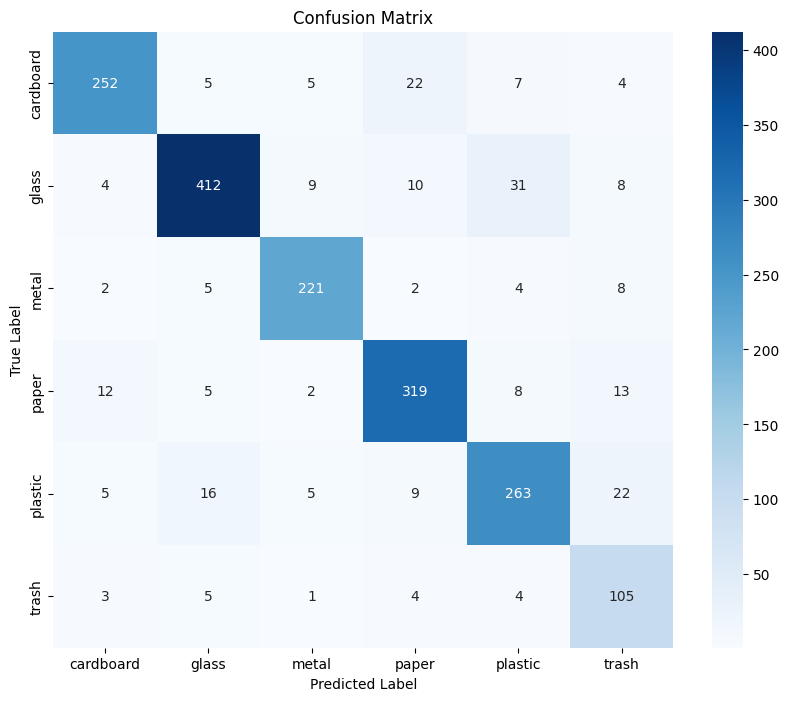

Confusion matrix saved at /content/test_confusion_matrix.png
Test Accuracy: 0.8675


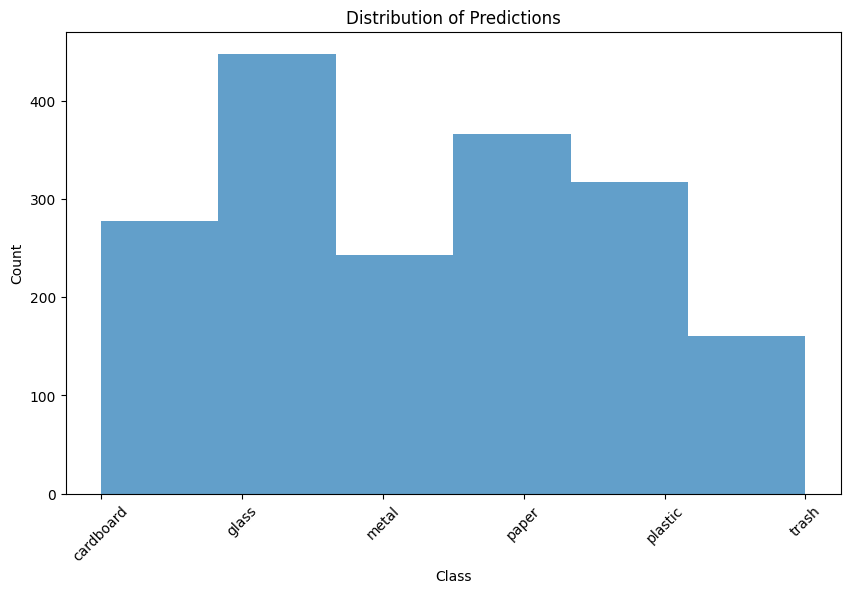

Prediction distribution saved at /content/test_prediction_distribution.png


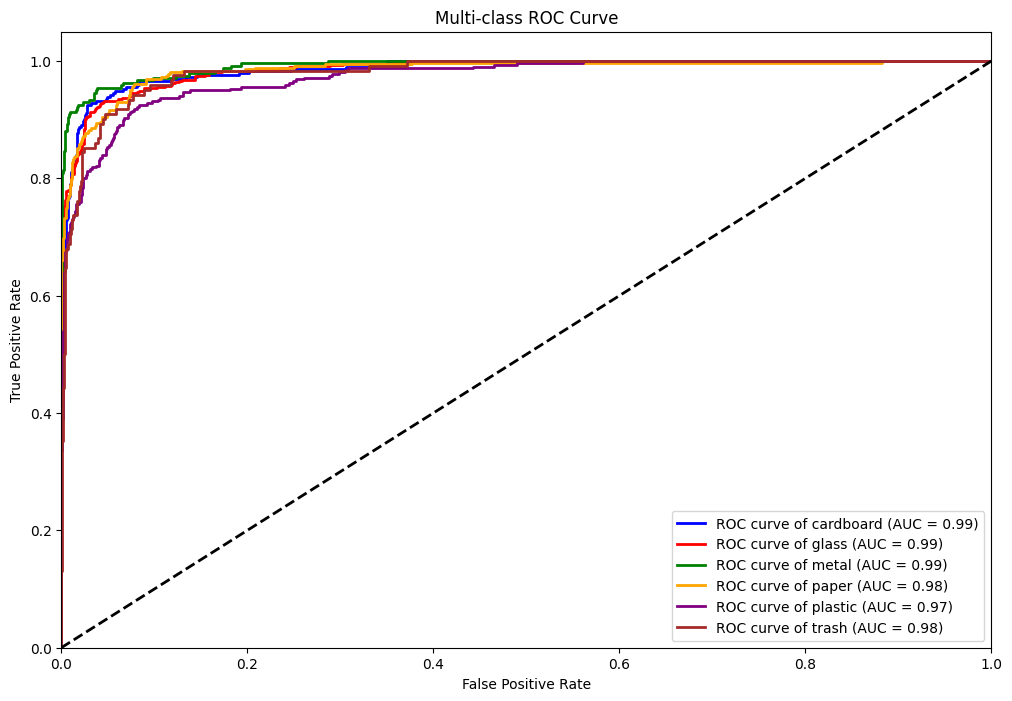

ROC curve saved at /content/test_roc_curve.png


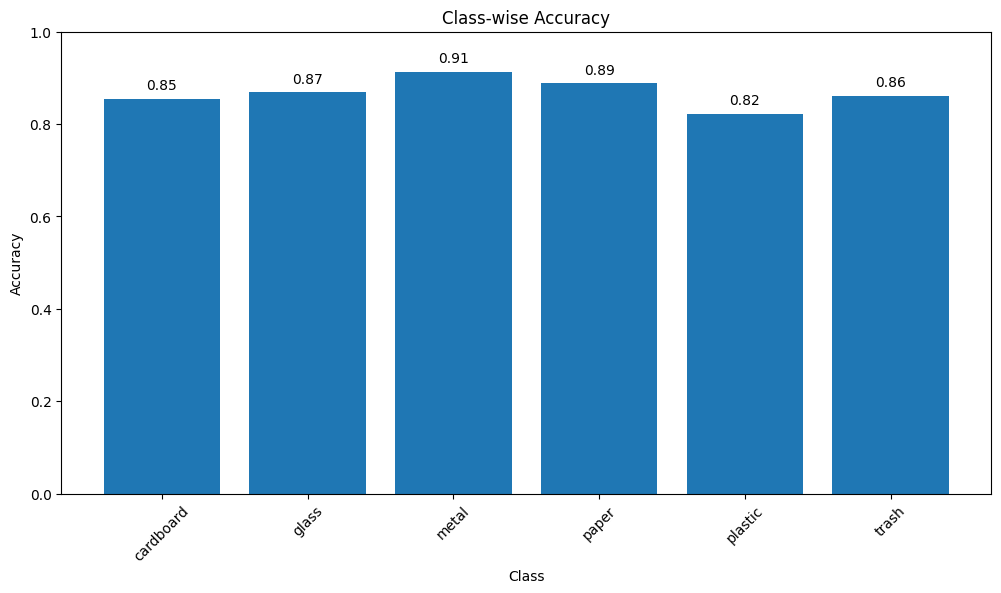

Class-wise accuracy plot saved at /content/test_class_accuracy.png
Test performance dashboard saved at /content/test_performance_dashboard.png
Testing complete!


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    roc_curve,
    auc
)
from itertools import cycle
from PIL import Image
import os

# Load the saved model
model_path = "/content/saved_model.h5"  # Update this path to where your model is saved
model = keras.models.load_model(model_path)

# Load test dataset
test_data_dir = "/content/Merged_Split/test"  # Update this path
batch_size = 32
img_size = (51, 51)  # Adjust based on your model's input size

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Only rescaling for test data
)

# Load the test dataset
test_dataset_tf = test_datagen.flow_from_directory(
    test_data_dir,  # Path to the test images
    target_size=(img_size[0], img_size[1]),
    batch_size=batch_size,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False  # No shuffle for test data
)

# Calculate steps per epoch for test dataset
steps_per_epoch_test = np.ceil(test_dataset_tf.samples / batch_size).astype(int)

# Get true labels and class names
true_labels = test_dataset_tf.classes
class_names = list(test_dataset_tf.class_indices.keys())
num_classes = len(class_names)

# Predict using the model with specified steps
y_pred_probs = model.predict(test_dataset_tf, steps=steps_per_epoch_test)  # Predicted probabilities
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Convert to class labels

# 1. **Classification Report**
print("Classification Report:")
report = classification_report(true_labels, y_pred_classes, target_names=class_names)
print(report)

# Save the classification report
report_path = "/content/classification_report.txt"
with open(report_path, "w") as f:
    f.write(report)
print(f"Classification report saved at {report_path}")

# 2. **Confusion Matrix**
cm = confusion_matrix(true_labels, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
confusion_matrix_path = "/content/test_confusion_matrix.png"
plt.savefig(confusion_matrix_path)
plt.show()  # Restored plt.show()
print(f"Confusion matrix saved at {confusion_matrix_path}")

# 3. **Accuracy, Precision, Recall, F1-score**
correct_predictions = np.sum(y_pred_classes == true_labels)
accuracy = correct_predictions / len(true_labels)

print(f"Test Accuracy: {accuracy:.4f}")

# 4. **Prediction Distribution**
plt.figure(figsize=(10, 6))
plt.hist(y_pred_classes, bins=num_classes, alpha=0.7)
plt.title("Distribution of Predictions")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(range(num_classes), class_names, rotation=45)
prediction_distribution_path = "/content/test_prediction_distribution.png"
plt.savefig(prediction_distribution_path)
plt.show()  # Restored plt.show()
print(f"Prediction distribution saved at {prediction_distribution_path}")

# 5. **ROC Curve for Multi-class Classification (One-vs-Rest)**
plt.figure(figsize=(12, 8))

# One-hot encode true labels
y_true_one_hot = tf.keras.utils.to_categorical(true_labels, num_classes)

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_one_hot[:, i], y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc="lower right")
roc_curve_path = "/content/test_roc_curve.png"
plt.savefig(roc_curve_path)
plt.show()  # Restored plt.show()
print(f"ROC curve saved at {roc_curve_path}")

# 6. **Class-wise Accuracy**
class_accuracy = []
for i in range(num_classes):
    mask = (true_labels == i)
    if np.sum(mask) > 0:
        accuracy = np.sum(y_pred_classes[mask] == i) / np.sum(mask)
        class_accuracy.append(accuracy)
    else:
        class_accuracy.append(0)

plt.figure(figsize=(12, 6))
plt.bar(range(num_classes), class_accuracy)
plt.title("Class-wise Accuracy")
plt.xlabel("Class")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(range(num_classes), class_names, rotation=45)
for i, v in enumerate(class_accuracy):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
class_accuracy_path = "/content/test_class_accuracy.png"
plt.savefig(class_accuracy_path)
plt.show()  # Restored plt.show()
print(f"Class-wise accuracy plot saved at {class_accuracy_path}")

# 7. **Create a Performance Summary Dashboard**
image_paths = [
    confusion_matrix_path,
    prediction_distribution_path,
    roc_curve_path,
    class_accuracy_path
]

existing_images = [path for path in image_paths if os.path.exists(path)]

if len(existing_images) >= 2:
    images = [Image.open(img) for img in existing_images]

    cols = min(2, len(images))
    rows = (len(images) + cols - 1) // cols

    widths = [max(images[j].width for j in range(i, min(i+cols, len(images))))
              for i in range(0, len(images), cols)]
    heights = [max(images[i*cols + j].height for j in range(min(cols, len(images) - i*cols)))
               for i in range(rows)]

    total_width = sum(widths)
    total_height = sum(heights)
    dashboard = Image.new('RGB', (total_width, total_height), (255, 255, 255))

    y_offset = 0
    for i in range(rows):
        x_offset = 0
        for j in range(cols):
            idx = i * cols + j
            if idx < len(images):
                dashboard.paste(images[idx], (x_offset, y_offset))
                x_offset += images[idx].width
        y_offset += max(images[i*cols].height for i in range(min(cols, len(images) - i*cols)))

    dashboard_path = "/content/test_performance_dashboard.png"
    dashboard.save(dashboard_path)

    print(f"Test performance dashboard saved at {dashboard_path}")
    dashboard.show()

print("Testing complete!")

In [ ]:
import shutil
import os

# Define the target directories in your Google Drive
train_dir = "/content/drive/MyDrive/paper1/Training"
test_dir = "/content/drive/MyDrive/paper1/Testing"

# Create directories if they don't exist
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Files to move
train_visuals = [
    "/content/training_history.png",
    "/content/f1_score_history.png",
    "/content/confusion_matrix.png",
    "/content/class_accuracy.png",
    "/content/prediction_distribution.png",
    "/content/model_performance_dashboard.png",

]

test_visuals = [
    "/content/classification_report.txt",
    "/content/test_confusion_matrix.png",
    "/content/test_class_accuracy.png",
    "/content/test_prediction_distribution.png",
    "/content/test_roc_curve.png",
    "/content/test_performance_dashboard.png"
]

# Move training visualizations
for file_path in train_visuals:
    if os.path.exists(file_path):
        shutil.copy(file_path, train_dir)

# Move testing visualizations
for file_path in test_visuals:
    if os.path.exists(file_path):
        shutil.copy(file_path, test_dir)

# Save the model again (optional)
model_path = '/content/saved_model.h5'
if os.path.exists(model_path):
    shutil.copy(model_path, test_dir)
    print(f"Saved model {model_path} to {test_dir}")

print("All testing visualizations and the model have been saved in Google Drive!")
print(f"✅ All visualizations copied to Google Drive:\n- Training: {train_dir}\n- Testing: {test_dir}")


Saved model /content/saved_model.h5 to /content/drive/MyDrive/paper1/Testing
All testing visualizations and the model have been saved in Google Drive!
✅ All visualizations copied to Google Drive:
- Training: /content/drive/MyDrive/paper1/Training
- Testing: /content/drive/MyDrive/paper1/Testing


In [ ]:
import random

# Set the random seeds for reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Generate random tensors with TensorFlow
random_tensor1 = tf.random.uniform((3, 3), minval=0, maxval=10, dtype=tf.int32)
print("Random Tensor 1:")
print(random_tensor1.numpy())

# Reset the seed and generate again
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

random_tensor2 = tf.random.uniform((3, 3), minval=0, maxval=10, dtype=tf.int32)
print("\nRandom Tensor 2:")
print(random_tensor2.numpy())

# Verify that the two tensors are identical
print("\nAre the tensors identical?")
print(np.array_equal(random_tensor1.numpy(), random_tensor2.numpy()))







import tensorflow as tf
from tensorflow import keras

# Define image dimensions
IMG_DIM = 224

layers = [
    # First Convolution layer
    keras.layers.Conv2D(64, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Dropout(0.25),

    # Second Convolution layer
    keras.layers.Conv2D(64, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Dropout(0.25),

    # Third Convolution layer
    keras.layers.Conv2D(128, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Dropout(0.25),

    # Fourth Convolution layer
    keras.layers.Conv2D(128, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Dropout(0.25),

    # Fifth Convolution layer
    keras.layers.Conv2D(256, kernel_size=(3, 3), strides=(1, 1), padding="same", activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Dropout(0.25),

    # Use GlobalAveragePooling2D instead of Flatten to handle the reduced feature map size
    keras.layers.GlobalAveragePooling2D(),

    # Fully connected layer
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.5),

    # Output layer (6 classes)
    keras.layers.Dense(6, activation='softmax')
]

keras_file = 'model.h5'
# Create the model
tf_model = keras.Sequential(layers)
# tf_model = quantize.quantize_apply(tf_model)

tf_model.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy', F1Score()],)

x = tf.random.uniform(shape=(BATCH_SIZE, IMG_DIM, IMG_DIM, 3), maxval=1, minval=0)
print(tf_model(x).shape)
keras.models.save_model(tf_model, keras_file)

# Print the model summary
tf_model.summary()


Random Tensor 1:
[[7 9 1]
 [6 2 4]
 [3 3 1]]

Random Tensor 2:
[[7 9 1]
 [6 2 4]
 [3 3 1]]

Are the tensors identical?
True


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


(16, 6)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 14, 14, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 7, 7, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 7, 7, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 588,998 (2.25 MB)

 Trainable params: 588,998 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tqdm.keras import TqdmCallback
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Calculate steps per epoch for training and validation
steps_per_epoch_train = np.ceil(train_dataset.samples / BATCH_SIZE).astype(int)
steps_per_epoch_val = np.ceil(val_dataset.samples / BATCH_SIZE).astype(int)

epochs = 150

# Train the model
history = tf_model.fit(
    train_dataset_tf,
    steps_per_epoch=steps_per_epoch_train,
    epochs=epochs,
    validation_data=val_dataset_tf,
    validation_steps=steps_per_epoch_val,
    callbacks=[TqdmCallback()],
)

# Save the model after training
keras.models.save_model(tf_model, keras_file)

# ---------------------
# Graph Generation
# ---------------------
history_dict = history.history
epoch_range = range(1, epochs + 1)

plt.figure(figsize=(15, 4))

# Plot Loss
plt.subplot(1, 3, 1)
plt.plot(epoch_range, history_dict['loss'], label='Training Loss')
plt.plot(epoch_range, history_dict['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot Accuracy
plt.subplot(1, 3, 2)
plt.plot(epoch_range, history_dict['accuracy'], label='Training Accuracy')
plt.plot(epoch_range, history_dict['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot F1 Score
# (Note: the exact key names may vary depending on the F1 metric implementation;
# adjust 'f1_score' and 'val_f1_score' if needed)
plt.subplot(1, 3, 3)
plt.plot(epoch_range, history_dict.get('f1_score', []), label='Training F1 Score')
plt.plot(epoch_range, history_dict.get('val_f1_score', []), label='Validation F1 Score')
plt.title('F1 Score over Epochs')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()

plt.tight_layout()
plt.show()

# ---------------------
# Classification Report on Test Data
# ---------------------
# Calculate steps for the test set
steps_per_epoch_test = np.ceil(test_dataset.samples / BATCH_SIZE).astype(int)

# Run predictions on the test dataset
predictions = tf_model.predict(test_dataset_tf, steps=steps_per_epoch_test)
y_pred = np.argmax(predictions, axis=1)

# Extract true labels from the test generator (assuming test_dataset has a 'classes' attribute)
y_true = test_dataset.classes

# Get class names from the training dataset
target_names = [name for name, index in sorted(train_dataset.class_indices.items(), key=lambda x: x[1])]

print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=target_names))

# ---------------------
# F1 Confidence Curve (Prediction Confidence Distribution)
# ---------------------
# Compute the confidence for each prediction (i.e. the maximum probability)
confidences = np.max(predictions, axis=1)

# Determine which predictions are correct
correct = (y_pred == y_true)

plt.figure(figsize=(8, 6))
plt.hist(confidences[correct], bins=20, alpha=0.7, label='Correct Predictions')
plt.hist(confidences[~correct], bins=20, alpha=0.7, label='Incorrect Predictions')
plt.title('Prediction Confidence Distribution')
plt.xlabel('Max Softmax Probability (Confidence)')
plt.ylabel('Frequency')
plt.legend()
plt.show()


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Epoch 1/150
905/905 ━━━━━━━━━━━━━━━━━━━━ 422s 461ms/step - accuracy: 0.2539 - f1_score: 0.1050 - loss: 1.7401 - val_accuracy: 0.2939 - val_f1_score: 0.1422 - val_loss: 1.6315
Epoch 2/150
905/905 ━━━━━━━━━━━━━━━━━━━━ 444s 491ms/step - accuracy: 0.3156 - f1_score: 0.1907 - loss: 1.6293 - val_accuracy: 0.3878 - val_f1_score: 0.3090 - val_loss: 1.5173
Epoch 3/150
905/905 ━━━━━━━━━━━━━━━━━━━━ 392s 433ms/step - accuracy: 0.4136 - f1_score: 0.3349 - loss: 1.4862 - val_accuracy: 0.5343 - val_f1_score: 0.4322 - val_loss: 1.2500
Epoch 4/150
905/905 ━━━━━━━━━━━━━━━━━━━━ 441s 488ms/step - accuracy: 0.5196 - f1_score: 0.4444 - loss: 1.2901 - val_accuracy: 0.5856 - val_f1_score: 0.5349 - val_loss: 1.1541
Epoch 5/150
905/905 ━━━━━━━━━━━━━━━━━━━━ 399s 441ms/step - accuracy: 0.5813 - f1_score: 0.5367 - loss: 1.1537 - val_accuracy: 0.6028 - val_f1_score: 0.5416 - val_loss: 1.0410
Epoch 6/150
905/905 ━━━━━━━━━━━━━━━━━━━━ 395s 437ms/step - accuracy: 0.6163 - f1_score: 0.5739 - loss: 1.0708 - val_accuracy:

In [ ]:
#পেপার লিঙ্ক https://jagst.utm.my/index.php/jagst/article/view/31/13

In [ ]:
pip install numpy==1.26.4 tensorflow==2.18.0 tensorflow-model-optimization==0.8.0 --force-reinstall

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 877.7 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.5/242.5 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.5/126.5 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 152.9/152.9 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2